# Task 1: Data Merge, Cleaning, EDA and Feature Engineering
**Formative 2: Multimodal Data Preprocessing** · Data lead: Sheja Queen Linda ([@Queenlinda12](https://github.com/Queenlinda12))

In this notebook I take the two files we were given, `customer_social_profiles` and `customer_transactions`,
and turn them into one clean dataset. Our product recommendation model uses it to predict which **product category** a customer will buy.

**Outputs:** `data/processed/merged_dataset.csv` (readable) and `data/processed/merged_dataset_model_ready.csv` (encoded and scaled).

I put the actual cleaning and merging code in `scripts/merge_pipeline.py`, so the notebook and the script always do exactly the same thing. Here I call those functions one step at a time and show what happens at each step.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import merge_pipeline as mp

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Load the raw data and inspect it

In [2]:
social_raw, trans_raw = mp.load_raw()
print("customer_social_profiles:", social_raw.shape)
print("customer_transactions:   ", trans_raw.shape)
display(social_raw.head())
display(trans_raw.head())

customer_social_profiles: (155, 5)
customer_transactions:    (150, 6)


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [3]:
# variable types, nulls and unique values for both files
display(pd.concat([mp.profile(social_raw, "social"), mp.profile(trans_raw, "transactions")], ignore_index=True))
print("Exact duplicate rows -> social:", social_raw.duplicated().sum(), "| transactions:", trans_raw.duplicated().sum())

,dataset,column,dtype,nulls,unique
0,social,customer_id_new,str,0,84
1,social,social_media_platform,str,0,5
2,social,engagement_score,int64,0,50
3,social,purchase_interest_score,float64,0,40
4,social,review_sentiment,str,0,3
5,transactions,customer_id_legacy,int64,0,75
6,transactions,transaction_id,int64,0,150
7,transactions,purchase_amount,int64,0,120
8,transactions,purchase_date,datetime64[us],0,150
9,transactions,product_category,str,0,5


Exact duplicate rows -> social: 5 | transactions: 0


In [4]:
# How many rows does each customer have?
print("Social rows per customer:\n", social_raw["customer_id_new"].value_counts().describe().round(2), sep="")
print("\nTransactions per customer:\n", trans_raw["customer_id_legacy"].value_counts().describe().round(2), sep="")

Social rows per customer:
count    84.00
mean      1.85
std       1.16
min       1.00
25%       1.00
50%       1.00
75%       2.00
max       7.00
Name: count, dtype: float64

Transactions per customer:
count    75.00
mean      2.00
std       1.12
min       1.00
25%       1.00
50%       2.00
75%       2.50
max       6.00
Name: count, dtype: float64


In [5]:
display(social_raw.describe(include="all").T)
display(trans_raw.describe().T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_new,155,84,A155,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
social_media_platform,155,5,Twitter,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engagement_score,155.0,NaN,NaN,NaN,75.606452,14.568021,50.0,63.5,77.0,87.5,99.0
purchase_interest_score,155.0,NaN,NaN,NaN,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0
review_sentiment,155,3,Positive,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,min,25%,50%,75%,max,std
customer_id_legacy,150.0,148.76,100.0,121.25,150.5,174.75,199.0,30.046425
transaction_id,150.0,1075.5,1001.0,1038.25,1075.5,1112.75,1150.0,43.445368
purchase_amount,150.0,280.78,51.0,179.0,274.0,388.5,495.0,121.329595
purchase_date,150,2024-03-15 12:00:00,2024-01-01 00:00:00,2024-02-07 06:00:00,2024-03-15 12:00:00,2024-04-21 18:00:00,2024-05-29 00:00:00,NaN
customer_rating,140.0,2.985,1.0,1.95,3.0,4.0,5.0,1.20699


**What I found when I looked at the raw files**

| Issue | Where | Fix |
|---|---|---|
| Different ID formats: `A151` vs `151` | both files | Strip the `A` prefix and cast both to an integer `customer_id` |
| 5 exact duplicate rows | social profiles | Drop them |
| 10 missing `customer_rating` values | transactions | Fill with the overall median and add a `rating_missing` flag |
| `purchase_date` stored as a date, categories stored as text | both | Cast to `datetime` and `category` |
| Several rows per customer in **both** tables (up to 7 social rows, up to 6 purchases) | both | Aggregate social profiles to one row per customer before joining |

The columns fall into **numeric** (`engagement_score`, `purchase_interest_score`, `purchase_amount`, `customer_rating`),
**categorical** (`social_media_platform`, `review_sentiment`, `product_category`), **date** (`purchase_date`) and **IDs**.

## 2. Clean both datasets

In [6]:
social = mp.clean_social(social_raw)
trans = mp.clean_transactions(trans_raw)

print(f"Social: {len(social_raw)} -> {len(social)} rows after dropping duplicates")
print(f"Transactions: {len(trans_raw)} -> {len(trans)} rows (no duplicates)")
print("Nulls left -> social:", social.isna().sum().sum(), "| transactions:", trans.isna().sum().sum())
print("Ratings filled with median:", trans["rating_missing"].sum())
display(pd.concat([mp.profile(social, "social (clean)"), mp.profile(trans, "transactions (clean)")], ignore_index=True))

Social: 155 -> 150 rows after dropping duplicates
Transactions: 150 -> 150 rows (no duplicates)
Nulls left -> social: 0 | transactions: 0
Ratings filled with median: 10


,dataset,column,dtype,nulls,unique
0,social (clean),social_media_platform,category,0,5
1,social (clean),engagement_score,int64,0,50
2,social (clean),purchase_interest_score,float64,0,40
3,social (clean),review_sentiment,category,0,3
4,social (clean),customer_id,int64,0,84
5,transactions (clean),customer_id,int64,0,75
6,transactions (clean),transaction_id,int64,0,150
7,transactions (clean),purchase_amount,int64,0,120
8,transactions (clean),purchase_date,datetime64[us],0,150
9,transactions (clean),product_category,str,0,5


**Why I used the overall median for the missing ratings:** I thought about filling them with the average rating for each product category,
but that uses the thing we're trying to predict, which is basically cheating. The overall median (3.0) is safer, and the `rating_missing` column still records which ratings were missing.

## 3. Aggregate social profiles to one row per customer

In [7]:
social_agg = mp.aggregate_social(social)
print(social_agg.shape, "-> customer_id unique:", social_agg["customer_id"].is_unique)
display(social_agg.head())

(84, 17) -> customer_id unique: True


,customer_id,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,avg_sentiment_score,share_negative,share_neutral,share_positive,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter,top_platform
0,100,2,2,77.0000,81,4.4000,4.4,-0.5000,0.5000,0.5000,0.0000,0,1,0,0,1,Instagram
1,101,1,1,68.0000,68,1.0000,1.0,0.0000,0.0000,1.0000,0.0000,0,0,0,0,1,Twitter
2,102,1,1,51.0000,51,4.8000,4.8,0.0000,0.0000,1.0000,0.0000,0,0,1,0,0,LinkedIn
3,103,3,2,64.3333,77,2.8667,3.6,0.3333,0.3333,0.0000,0.6667,1,1,0,0,0,Instagram
4,104,3,2,83.0000,91,2.9333,4.6,-0.6667,0.6667,0.3333,0.0000,1,0,0,0,1,Twitter


This step matters a lot. A customer can have a profile on several platforms, and they can also have several purchases. If I joined
the raw tables, a customer with 3 profiles and 2 purchases would turn into 6 rows, and each purchase would be counted three times.
So I summarised each customer's profiles into one row first. After that, every transaction matches exactly one row (a **many-to-one** join).
The summary includes their average and highest engagement and purchase interest, the share of positive, neutral and negative reviews, which platforms they use, and the platform they're most engaged on.

## 4. Merge and justify the join type

In [8]:
merged = mp.merge(trans, social_agg)          # inner join, validate="many_to_one"
checks = mp.merge_checks(trans, social_agg, merged)
pd.Series(checks, name="value").to_frame()

,value
transactions_rows_before,150
social_customers_after_aggregation,84
customers_in_both,61
customers_only_in_transactions,14
customers_only_in_social,23
transactions_without_social_profile,33
merged_rows,117
merged_customers,61
transaction_id_unique_after_merge,True
nulls_after_merge,0


In [9]:
# Compare join types before choosing
for how in ["inner", "left", "right", "outer"]:
    j = trans.merge(social_agg, on="customer_id", how=how)
    print(f"{how:>5} join: {len(j):>3} rows, {j.isna().any(axis=1).sum():>3} rows with missing values")

inner join: 117 rows,   0 rows with missing values
 left join: 150 rows,  33 rows with missing values
right join: 140 rows,  23 rows with missing values
outer join: 173 rows,  56 rows with missing values


**Why I chose an inner join on `customer_id`**

* Our model predicts *what a customer buys when they visit our social media sites*, so every row needs **both**
  a purchase (the answer) and social media behaviour (the clues).
* A **left** join would keep 33 purchases from 14 customers who have no social profile at all. All their social columns would be empty,
  and filling them in would mean making up behaviour that never happened.
* A **right** or **outer** join would add 23 customers who never bought anything, so those rows would have no target.
* The inner join keeps **117 of 150 transactions (78%) from 61 customers**, with no missing values. Every `transaction_id` is still unique, so nothing was duplicated. Losing 22% isn't ideal, but real data beats invented data.

### Post-merge validation

In [10]:
assert merged["transaction_id"].is_unique, "a transaction was duplicated by the join"
assert merged.isna().sum().sum() == 0, "nulls after merge"
assert len(merged) == checks["transactions_rows_before"] - checks["transactions_without_social_profile"]
assert set(merged["customer_id"]) == set(trans["customer_id"]) & set(social_agg["customer_id"])

# spot check one customer: values in the merged row equal the source tables
cid = merged["customer_id"].iloc[0]
src = social[social["customer_id"] == cid]
row = merged[merged["customer_id"] == cid].iloc[0]
assert np.isclose(row["avg_engagement"], src["engagement_score"].mean())
print("All post-merge checks passed. Spot-checked customer", cid)
display(merged.sample(5, random_state=1))

All post-merge checks passed. Spot-checked customer 151


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_missing,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,avg_sentiment_score,share_negative,share_neutral,share_positive,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter,top_platform
69,113,1087,489,2024-03-27,Books,4.1,0,2,2,74.0,98,1.8500,2.7,0.5000,0.0000,0.5000,0.5,1,1,0,0,0,Facebook
46,152,1058,308,2024-02-27,Clothing,4.8,0,2,2,88.0,95,4.1500,4.2,1.0000,0.0000,0.0000,1.0,1,1,0,0,0,Facebook
58,101,1073,145,2024-03-13,Books,2.1,0,1,1,68.0,68,1.0000,1.0,0.0000,0.0000,1.0000,0.0,0,0,0,0,1,Twitter
114,104,1148,409,2024-05-27,Clothing,1.4,0,3,2,83.0,91,2.9333,4.6,-0.6667,0.6667,0.3333,0.0,1,0,0,0,1,Twitter
73,177,1092,179,2024-04-01,Clothing,4.0,0,2,2,71.0,77,1.3500,1.4,1.0000,0.0000,0.0000,1.0,0,0,1,0,1,LinkedIn


## 5. Exploratory data analysis

In [11]:
display(merged.describe().T.round(2))

,count,mean,min,25%,50%,75%,max,std
customer_id,117.0,147.91453,100.0,117.0,146.0,180.0,199.0,32.288722
transaction_id,117.0,1074.25641,1001.0,1036.0,1073.0,1113.0,1150.0,44.27328
purchase_amount,117.0,287.905983,62.0,183.0,280.0,397.0,495.0,120.084165
purchase_date,117,2024-03-14 06:09:13.846153,2024-01-01 00:00:00,2024-02-05 00:00:00,2024-03-13 00:00:00,2024-04-22 00:00:00,2024-05-29 00:00:00,NaN
customer_rating,117.0,3.108547,1.0,2.1,3.2,4.1,5.0,1.195723
rating_missing,117.0,0.068376,0.0,0.0,0.0,0.0,1.0,0.253476
n_social_profiles,117.0,1.820513,1.0,1.0,2.0,2.0,4.0,0.896501
n_platforms,117.0,1.598291,1.0,1.0,1.0,2.0,4.0,0.731788
avg_engagement,117.0,74.15456,50.0,66.5,77.0,83.0,99.0,12.674782
max_engagement,117.0,80.264957,50.0,68.0,82.0,95.0,99.0,15.87092


### Plot 1: Target distribution

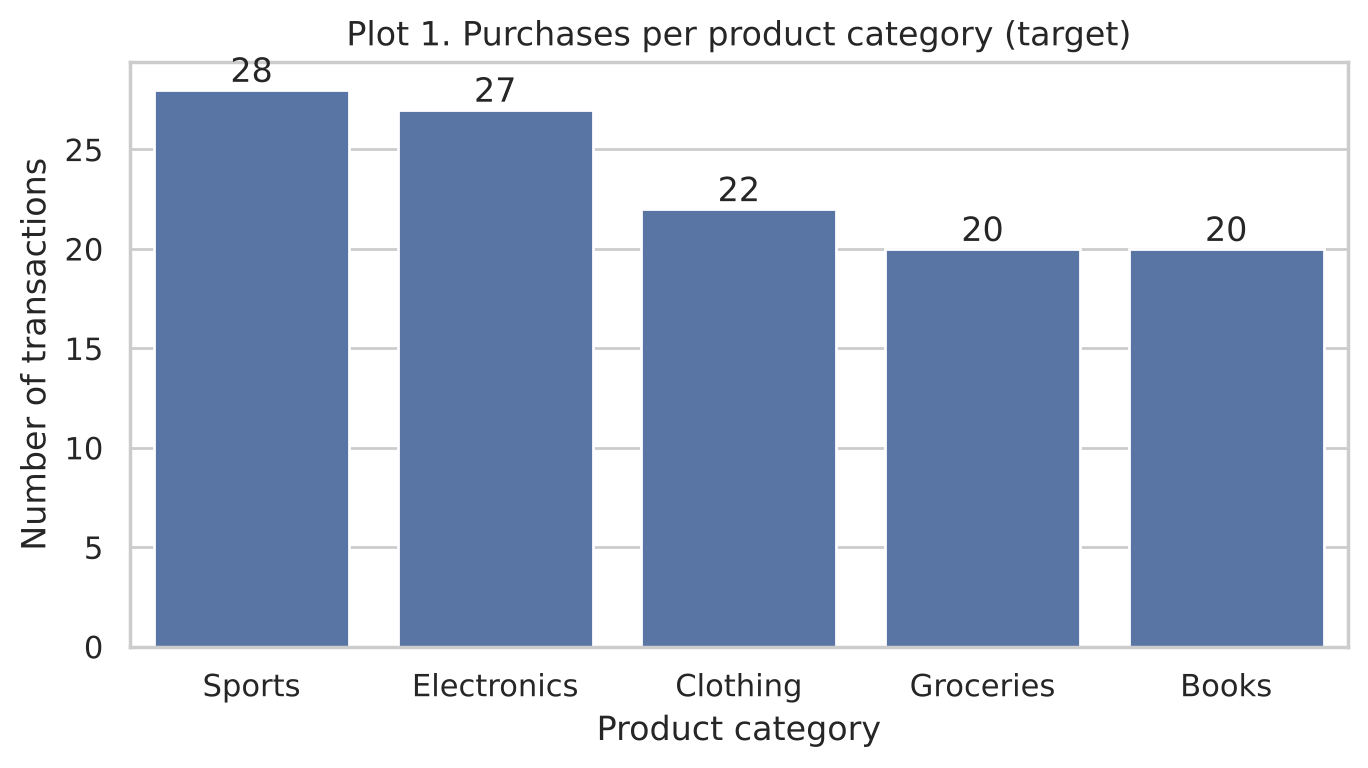

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
order = merged["product_category"].value_counts().index
sns.countplot(data=merged, x="product_category", order=order, ax=ax, color="#4C72B0")
ax.bar_label(ax.containers[0])
ax.set(title="Plot 1. Purchases per product category (target)", xlabel="Product category", ylabel="Number of transactions")
plt.tight_layout(); plt.savefig(FIG / "01_target_distribution.png", dpi=150); plt.show()

**What I see:** the five categories are fairly balanced (Sports 28, Electronics 27, Clothing 22, Books 20, Groceries 20).
The biggest one is only 24% of the rows, so we don't need any resampling, and accuracy and macro F1 are both fair to use.

### Plot 2: Distributions of the main numeric features

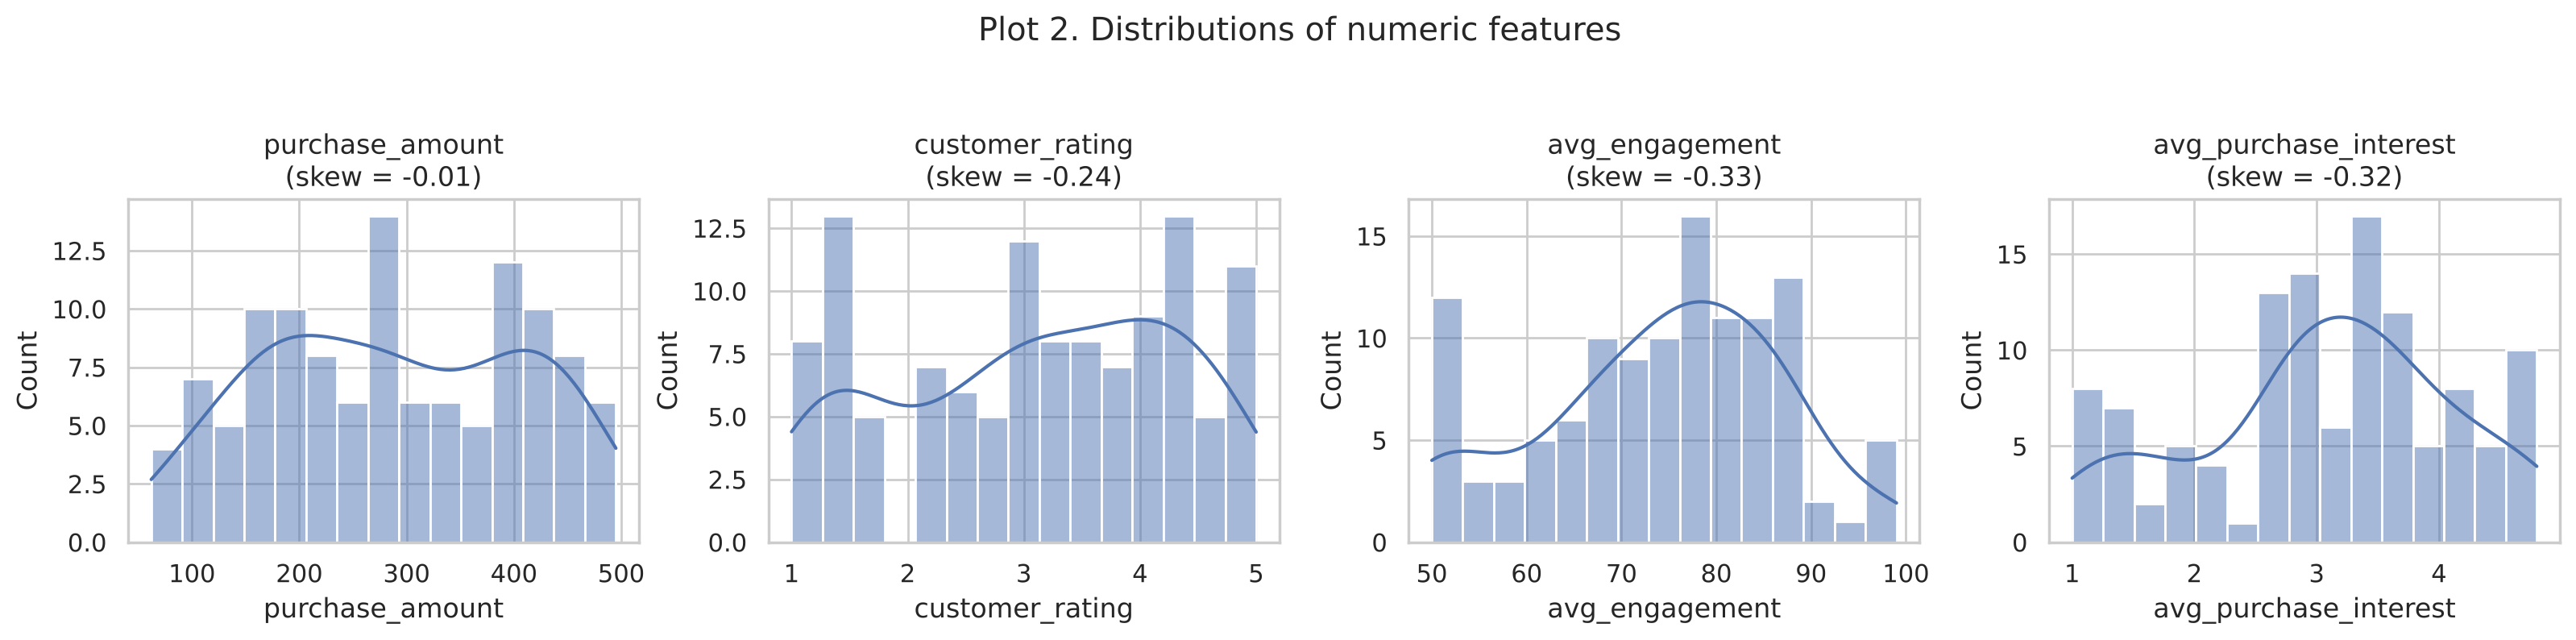

In [13]:
cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, cols):
    sns.histplot(merged[c], kde=True, ax=ax, bins=15)
    ax.set(title=f"{c}\n(skew = {merged[c].skew():.2f})", xlabel=c, ylabel="Count")
fig.suptitle("Plot 2. Distributions of numeric features", y=1.04)
plt.tight_layout(); plt.savefig(FIG / "02_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

**What I see:** `purchase_amount` is spread almost evenly between about 60 and 495 (skew close to 0). Engagement
(50 to 99) and purchase interest (1 to 5) are slightly left-skewed, with a small tail of low-scoring customers.
The columns also use very different scales (hundreds vs 1 to 5), so I standardised them in the model-ready file.

### Plot 3: Outlier check (box plots + IQR rule)

,column,lower_bound,upper_bound,n_outliers
0,purchase_amount,-138.00,718.00,0
1,customer_rating,-0.90,7.10,0
2,avg_engagement,41.75,107.75,0
3,avg_purchase_interest,1.12,5.25,4
4,customer_total_spend,-209.00,1503.00,5


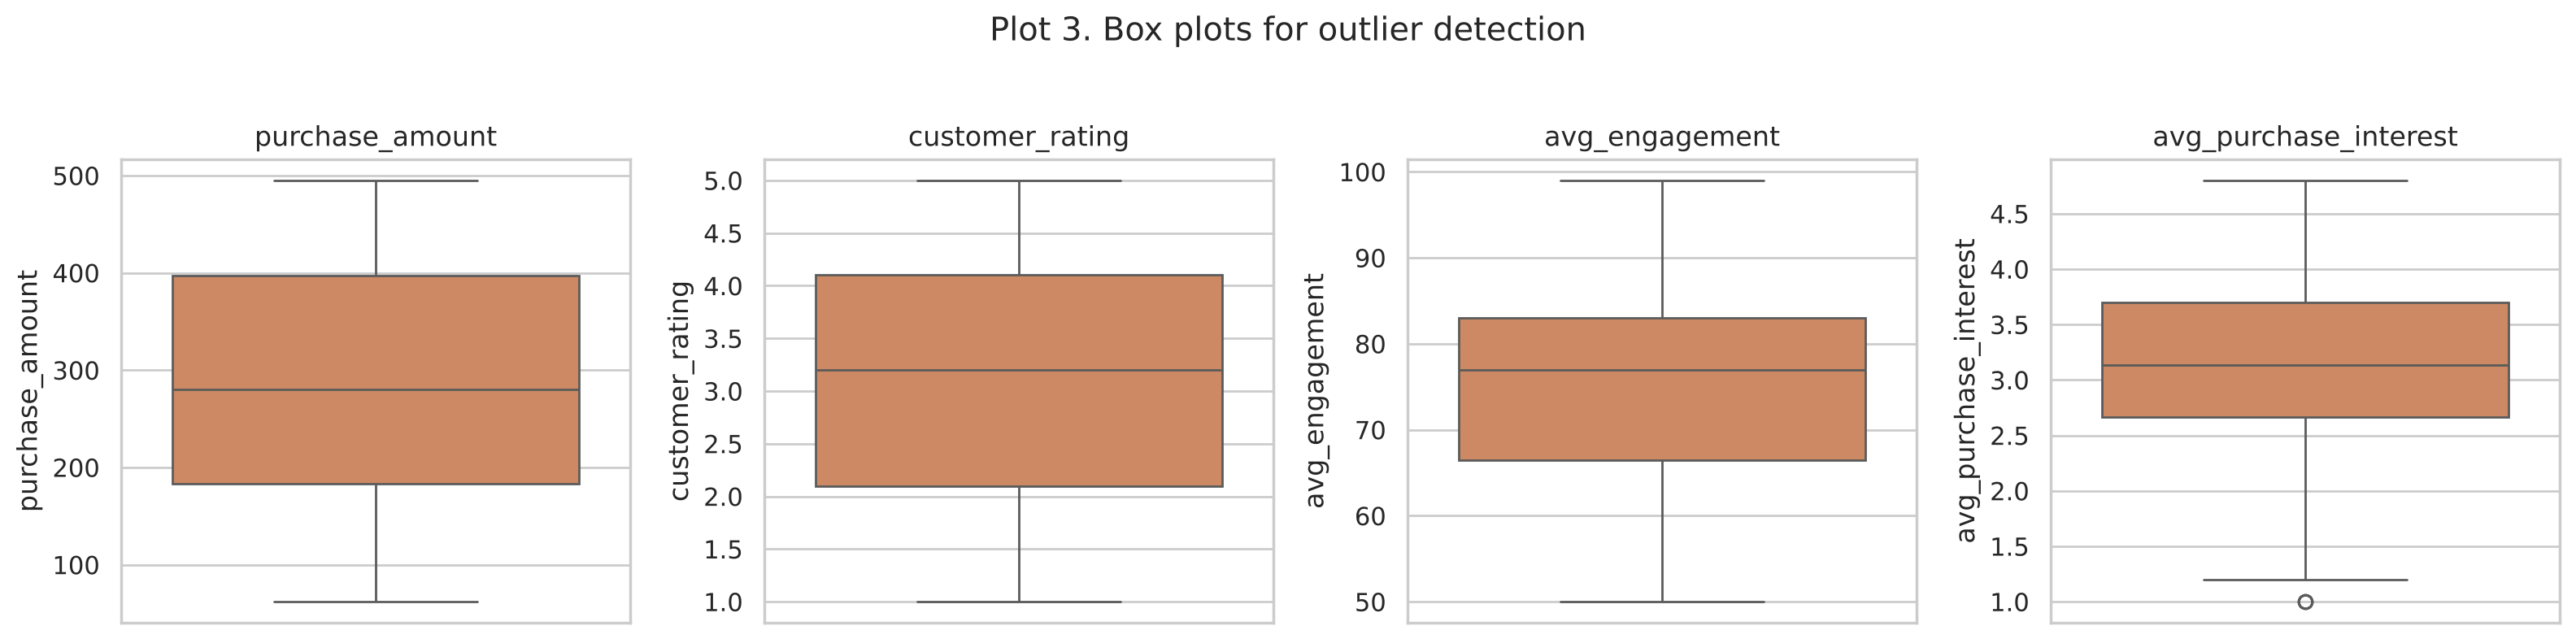

In [14]:
out_cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest", "customer_total_spend"]
display(mp.outlier_report(merged.assign(customer_total_spend=merged.groupby("customer_id")["purchase_amount"].transform("sum")), out_cols))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, cols):
    sns.boxplot(y=merged[c], ax=ax, color="#DD8452")
    ax.set(title=c, ylabel=c)
fig.suptitle("Plot 3. Box plots for outlier detection", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "03_outliers_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

**What I see:** by the 1.5 × IQR rule, `purchase_amount`, `customer_rating` and `avg_engagement` have **no outliers**.
There are 4 rows with `avg_purchase_interest` = 1.0 and one customer (ID 187) whose total spend of 1,863 comes from 5 purchases.
They look like real customers, not typing mistakes, so I **kept** them. With only 117 rows, I didn't want to throw away real data.

### Plot 4: Correlation heatmap

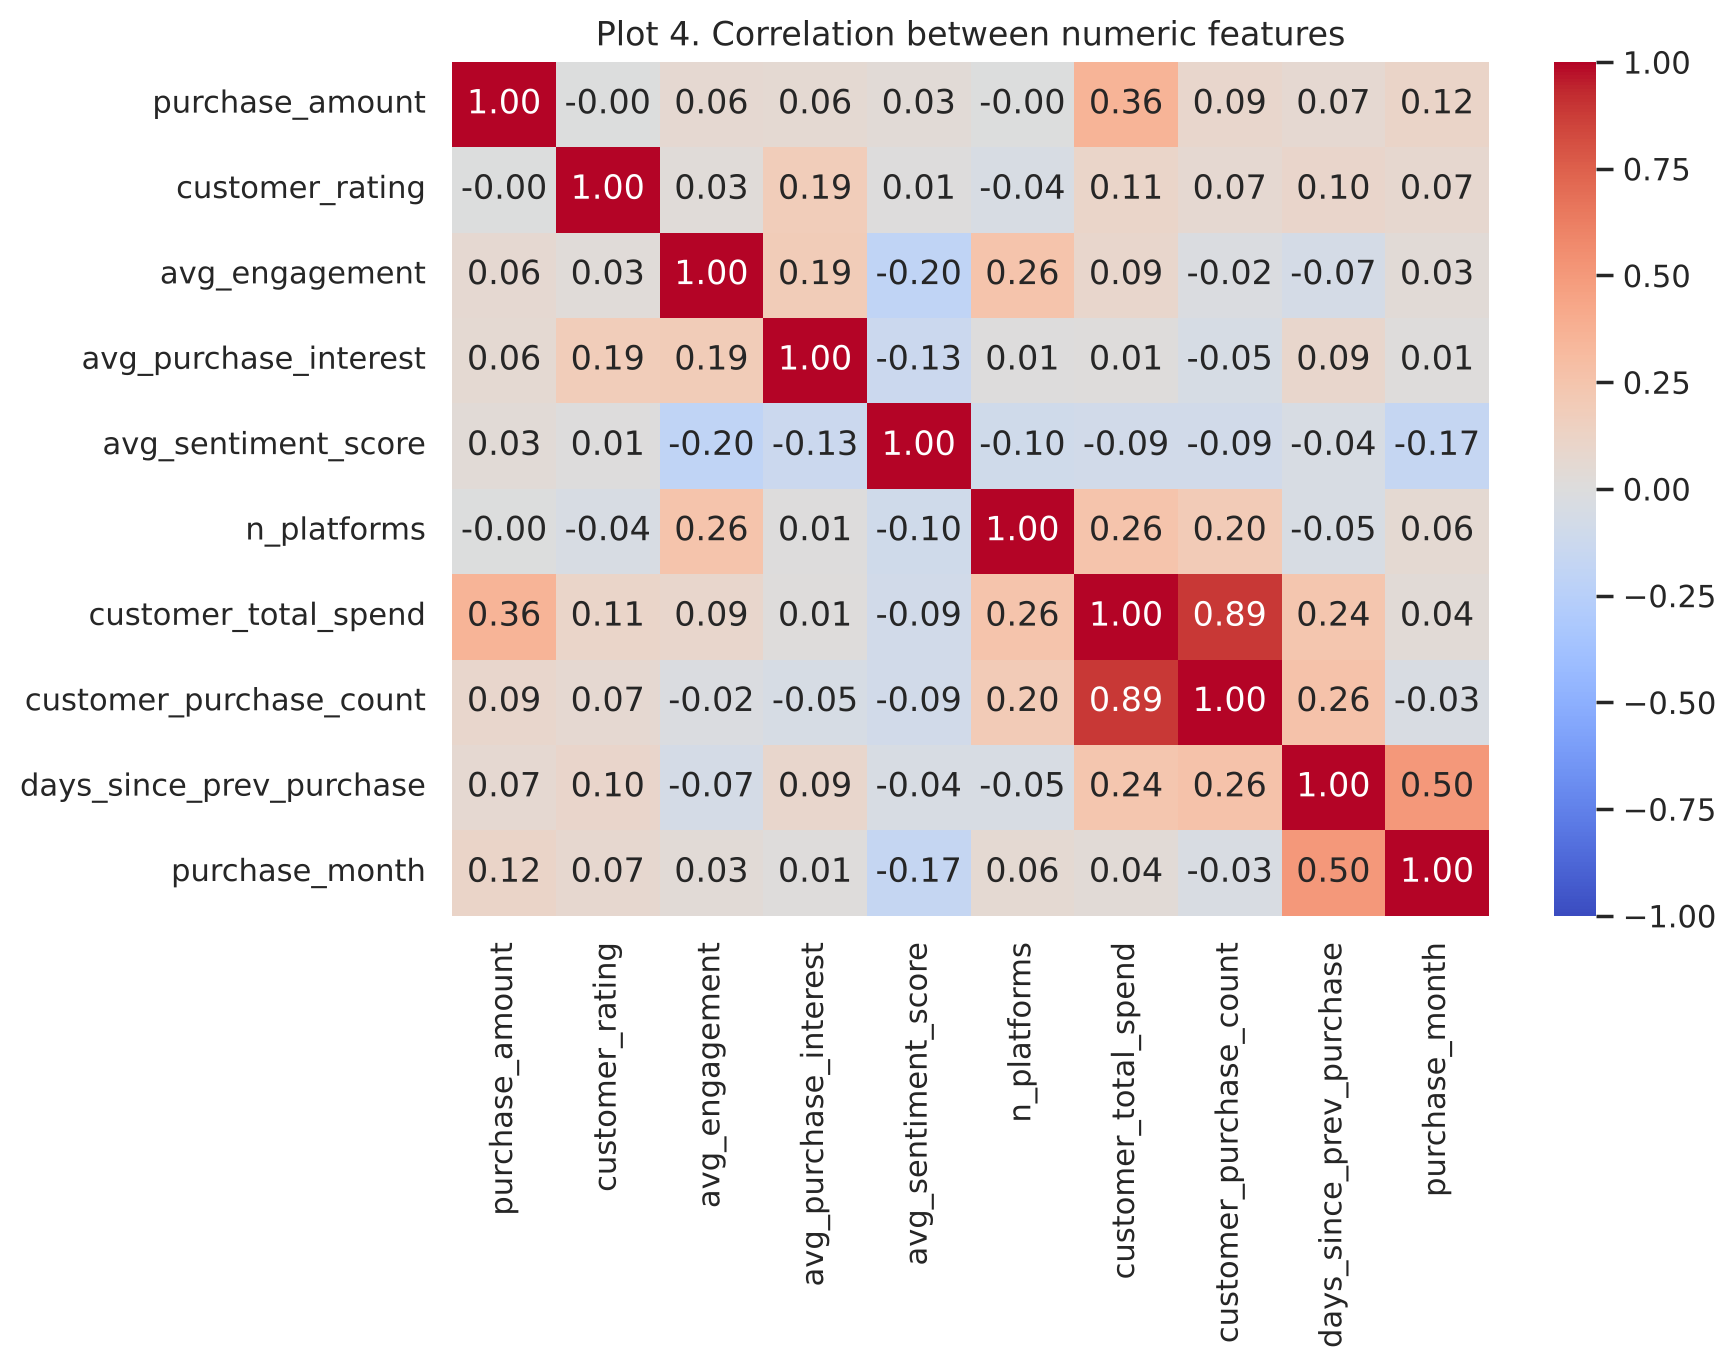

In [15]:
corr_cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest", "avg_sentiment_score",
             "n_platforms", "customer_total_spend", "customer_purchase_count", "days_since_prev_purchase", "purchase_month"]
feat = mp.engineer(merged)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(feat[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Plot 4. Correlation between numeric features")
plt.tight_layout(); plt.savefig(FIG / "04_correlation_heatmap.png", dpi=150); plt.show()

**What I see:** most features barely move together (|r| < 0.3), which is good because each one brings something different.
The one strong pair is `customer_total_spend` and `customer_purchase_count` (r = 0.89): customers who buy more often spend more in total.
That makes sense, but it means they overlap. Tree models are fine with that, but for logistic regression one of them could be dropped.
`days_since_prev_purchase` rises with `purchase_month` (r = 0.50) because later months give more time since a previous purchase.

### Plot 5: How features differ by product category

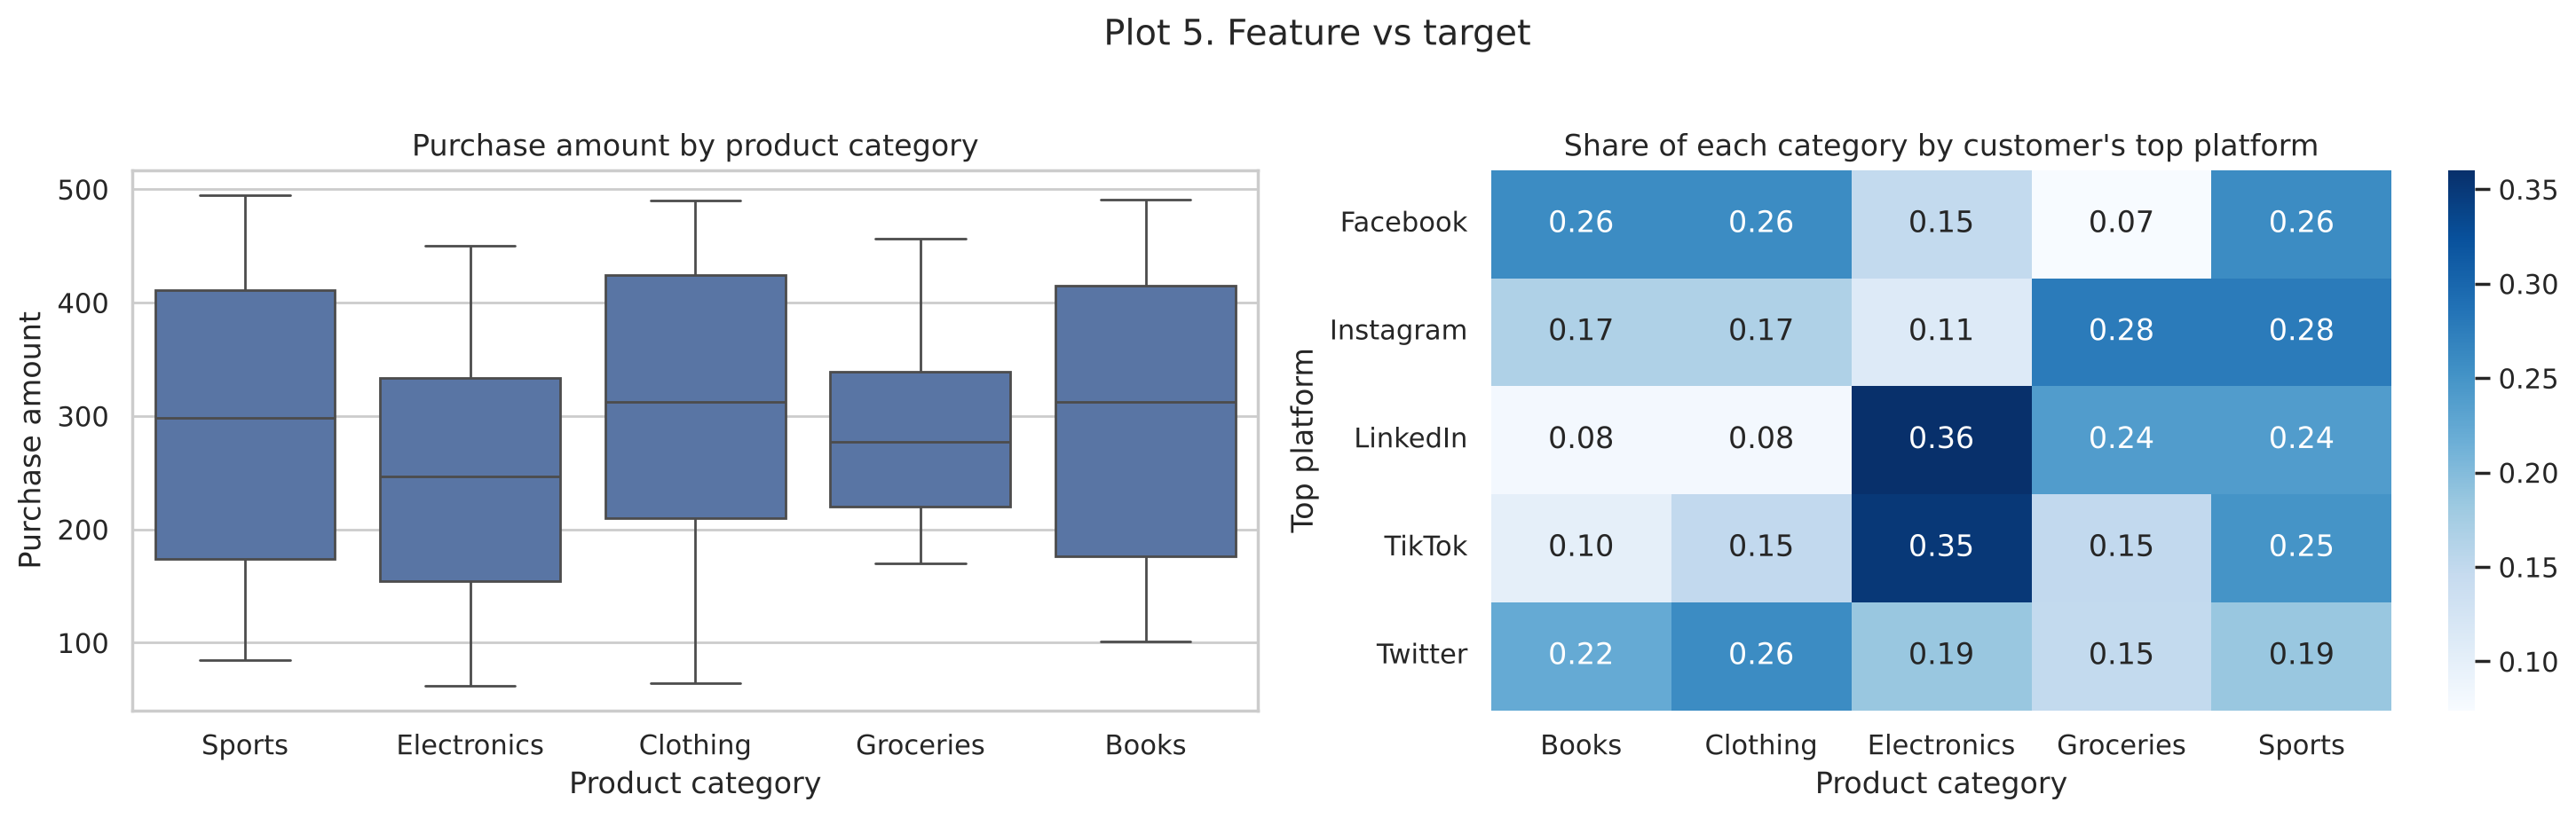

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=merged, x="product_category", y="purchase_amount", ax=axes[0], order=order)
axes[0].set(title="Purchase amount by product category", xlabel="Product category", ylabel="Purchase amount")
ct = pd.crosstab(merged["top_platform"], merged["product_category"], normalize="index")
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set(title="Share of each category by customer's top platform", xlabel="Product category", ylabel="Top platform")
fig.suptitle("Plot 5. Feature vs target", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "05_feature_vs_target.png", dpi=150, bbox_inches="tight"); plt.show()

**What I see:** median purchase amounts overlap a lot across categories, with Electronics the lowest on average (about 250 vs about 310 for Clothing and Books).
Platform shows more pattern: customers whose top platform is LinkedIn or TikTok buy Electronics most often (36% and 35%), and Instagram users lean towards Groceries and Sports.
So there is some signal, but it's weak, and I'd expect the product model to beat random guessing (24%) by only a small margin.

## 6. Feature engineering

In [17]:
final = mp.engineer(merged)
new_cols = ["purchase_month", "purchase_dayofweek", "is_weekend", "customer_total_spend", "customer_purchase_count",
            "customer_avg_spend", "amount_vs_customer_avg", "purchase_number", "days_since_prev_purchase",
            "engagement_x_interest", "target_code"]
display(final[["customer_id", "transaction_id", "purchase_amount"] + new_cols].head())
print("Target classes:", dict(enumerate(sorted(final["product_category"].unique()))))

,customer_id,transaction_id,purchase_amount,purchase_month,purchase_dayofweek,is_weekend,customer_total_spend,customer_purchase_count,customer_avg_spend,amount_vs_customer_avg,purchase_number,days_since_prev_purchase,engagement_x_interest,target_code
0,151,1001,408,1,0,0,408,1,408.00,1.0000,1,-1,155.2802,4
1,192,1002,332,1,1,0,823,2,411.50,0.8068,1,-1,258.0000,2
2,114,1003,442,1,2,0,1034,4,258.50,1.7099,1,-1,417.6000,2
3,160,1005,64,1,4,0,64,1,64.00,1.0000,1,-1,181.6668,1
4,120,1006,395,1,5,1,760,3,253.33,1.5592,1,-1,205.3359,3


Target classes: {0: 'Books', 1: 'Clothing', 2: 'Electronics', 3: 'Groceries', 4: 'Sports'}


| Feature group | Features | Why |
|---|---|---|
| Social aggregates | avg/max engagement, avg/max interest, sentiment score and shares, platform flags, `top_platform`, `n_platforms` | Summarise each customer's social behaviour in one row |
| Spending aggregates | `customer_total_spend`, `customer_purchase_count`, `customer_avg_spend`, `amount_vs_customer_avg` | Requested per-customer aggregates; show whether this purchase is larger or smaller than usual |
| History | `purchase_number`, `days_since_prev_purchase` (-1 = first purchase) | Repeat vs new behaviour |
| Date | `purchase_month`, `purchase_dayofweek`, `is_weekend` | Seasonal and weekly patterns |
| Interaction | `engagement_x_interest` | Engaged and interested customers together |
| Target | `product_category` (text), `target_code` (0 to 4) | Clear label for the model |

None of these use `product_category`, so the model can't cheat by seeing the answer.

In [18]:
ready, num_features = mp.model_ready(final)
print("Scaled numeric features:", len(num_features))
print("Model-ready shape:", ready.shape)
display(ready.head())
print("Means after scaling (approx. 0):", ready[num_features].mean().abs().max().round(6))

Scaled numeric features: 21
Model-ready shape: (117, 37)


,transaction_id,customer_id,purchase_amount,customer_rating,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,avg_sentiment_score,share_negative,share_neutral,share_positive,purchase_month,purchase_dayofweek,customer_total_spend,customer_purchase_count,customer_avg_spend,amount_vs_customer_avg,purchase_number,days_since_prev_purchase,engagement_x_interest,rating_missing,is_weekend,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter,top_platform_Facebook,top_platform_Instagram,top_platform_LinkedIn,top_platform_TikTok,top_platform_Twitter,product_category,target_code
0,1001,151,1.00438,-0.67911,1.32132,0.55130,-0.19713,0.10979,-0.87955,0.09224,-0.58643,0.08089,1.00001,-0.92734,-1.34742,-1.44753,-0.77488,-1.31907,1.45119,0.00001,-0.79676,-0.68161,-0.81504,0,0,0,0,0,1,1,0,0,0,0,1,Sports,4
1,1002,192,0.36877,0.91672,-0.91918,-0.82109,-1.12155,-1.28235,1.18122,0.70146,1.20163,-0.76115,-0.78619,1.36085,-1.34742,-0.94794,0.31641,-0.37803,1.49349,-0.61306,-0.79676,-0.68161,0.29591,0,0,0,1,0,0,0,0,1,0,0,0,Electronics,2
2,1003,114,1.28874,-0.84709,-0.91918,-0.82109,1.01782,0.42619,1.66423,1.13662,-1.48053,1.76521,-0.78619,-0.92734,-1.34742,-0.44835,0.87125,1.50406,-0.35534,2.25268,-0.79676,-0.68161,2.02203,0,0,1,0,0,0,0,1,0,0,0,0,Electronics,2
3,1005,160,-1.87260,-1.51902,1.32132,1.92370,-0.11789,0.55275,-0.55758,-0.51698,0.30753,-0.76115,1.00001,-0.16469,-1.34742,0.55083,-1.67946,-1.31907,-2.70564,0.00001,-0.79676,-0.68161,-0.52966,0,0,0,1,1,1,0,0,1,0,0,0,Clothing,1
4,1006,120,0.89566,-1.68700,1.32132,0.55130,0.22546,0.74259,-0.39655,0.09224,1.20163,-0.76115,-0.78619,1.36085,-1.34742,1.05042,0.15074,0.56302,-0.41781,1.77447,-0.79676,-0.68161,-0.27367,0,1,1,1,0,0,0,0,1,0,0,0,Groceries,3


Means after scaling (approx. 0): 2e-06


## 7. Save

In [19]:
out = ROOT / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)
final.to_csv(out / "merged_dataset.csv", index=False)
ready.to_csv(out / "merged_dataset_model_ready.csv", index=False)
print("Saved:", (out / "merged_dataset.csv").name, final.shape, "|", (out / "merged_dataset_model_ready.csv").name, ready.shape)

Saved: merged_dataset.csv (117, 34) | merged_dataset_model_ready.csv (117, 37)


## Summary, and notes for the product model (Member D)

* **117 transactions × 34 columns** from 61 customers, with no nulls and no duplicated transactions.
* For training, use `merged_dataset_model_ready.csv`: drop `transaction_id`, `customer_id` and `product_category`, and use `target_code` as `y`.
* Scaling was fitted on all rows for convenience. Tree models (Random Forest, XGBoost) are unaffected. For logistic regression, refit `StandardScaler` on the training split only, inside a `Pipeline`.
* The same customer appears in several rows. Because of the per-customer features, a `GroupKFold` split by `customer_id` gives the most honest test score.
* Heads up: a quick Random Forest got about 37% accuracy (random guessing gets 24%). Low scores come from the provided data, not a bug.